In [28]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

df_train = pd.read_csv("data/buchungen.csv")
df_test = pd.read_csv("data/buchungen_test.csv")  # Test-Datensatz ohne Storniert-Status

display(df_train.dtypes)  # Ausgabe der Spalten und deren jeweiligen Datentyp
display(df_train)

hotel_typ                          str
storniert                        int64
anreisedatum                       str
vorlaufzeit_tage                 int64
naechte_wochenende               int64
naechte_wochentag                int64
erwachsene                       int64
kinder                         float64
babys                            int64
verpflegung                        str
herkunftsland                      str
marktsegment                       str
buchungskanal                      str
stammgast                        int64
frueh_stornierungen              int64
frueh_buchungen_eingehalten      int64
gebuchter_zimmertyp                str
zugewiesener_zimmertyp             str
buchungsaenderungen              int64
anzahlungsart                      str
agentur_id                     float64
warteliste_tage                  int64
kundentyp                          str
durchschn_tagespreis           float64
parkplaetze_benoetigt            int64
anzahl_sonderwuensche    

,hotel_typ,storniert,anreisedatum,vorlaufzeit_tage,naechte_wochenende,naechte_wochentag,erwachsene,kinder,babys,verpflegung,...,buchungsaenderungen,anzahlungsart,agentur_id,warteliste_tage,kundentyp,durchschn_tagespreis,parkplaetze_benoetigt,anzahl_sonderwuensche,reservierungsstatus,reservierungsstatus_datum
0,Ferienhotel,0,2015-07-01,340,0,0,2,0.0,0,Frühstück,...,3,Ohne Anzahlung,NaN,0,Einzelbucher,0.61,0,0,Ausgecheckt,2015-07-01
1,Ferienhotel,0,2015-07-01,738,0,0,2,0.0,0,Frühstück,...,4,Ohne Anzahlung,NaN,0,Einzelbucher,0.97,0,0,Ausgecheckt,2015-07-01
2,Ferienhotel,0,2015-07-01,14,0,1,1,0.0,0,Frühstück,...,0,Ohne Anzahlung,304.0,0,Einzelbucher,75.98,0,0,Ausgecheckt,2015-07-02
3,Ferienhotel,0,2015-07-01,14,0,2,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,240.0,0,Einzelbucher,98.18,0,1,Ausgecheckt,2015-07-03
4,Ferienhotel,0,2015-07-01,0,0,2,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,NaN,0,Einzelbucher,106.52,0,0,Ausgecheckt,2015-07-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95507,Stadthotel,0,2017-08-30,22,2,5,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,394.0,0,Einzelbucher,95.82,0,2,Ausgecheckt,2017-09-06
95508,Stadthotel,0,2017-08-30,21,2,5,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,394.0,0,Einzelbucher,96.24,0,0,Ausgecheckt,2017-09-06
95509,Stadthotel,0,2017-08-31,32,2,5,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,9.0,0,Einzelbucher,157.43,0,4,Ausgecheckt,2017-09-07
95510,Stadthotel,0,2017-08-31,110,2,5,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,89.0,0,Einzelbucher,104.14,0,0,Ausgecheckt,2017-09-07


Stornierungsraten
Gesamt:       37.04 %
Ferienhotel:   9.38 %
Stadthotel:   27.67 %



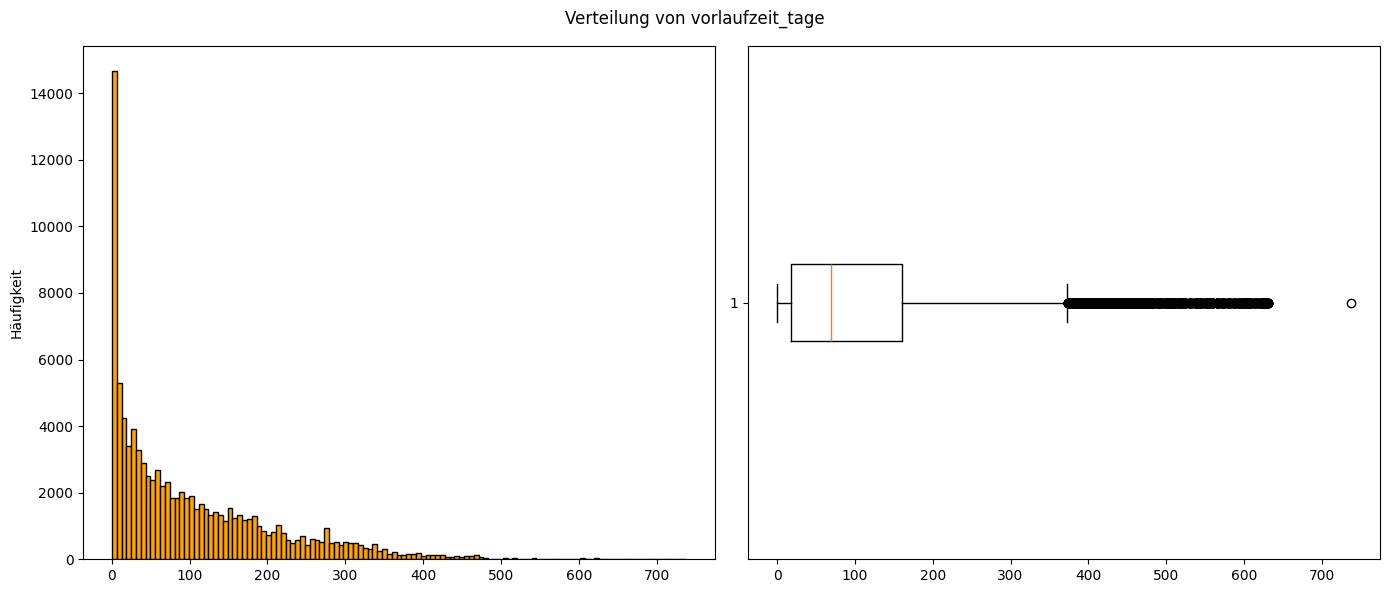

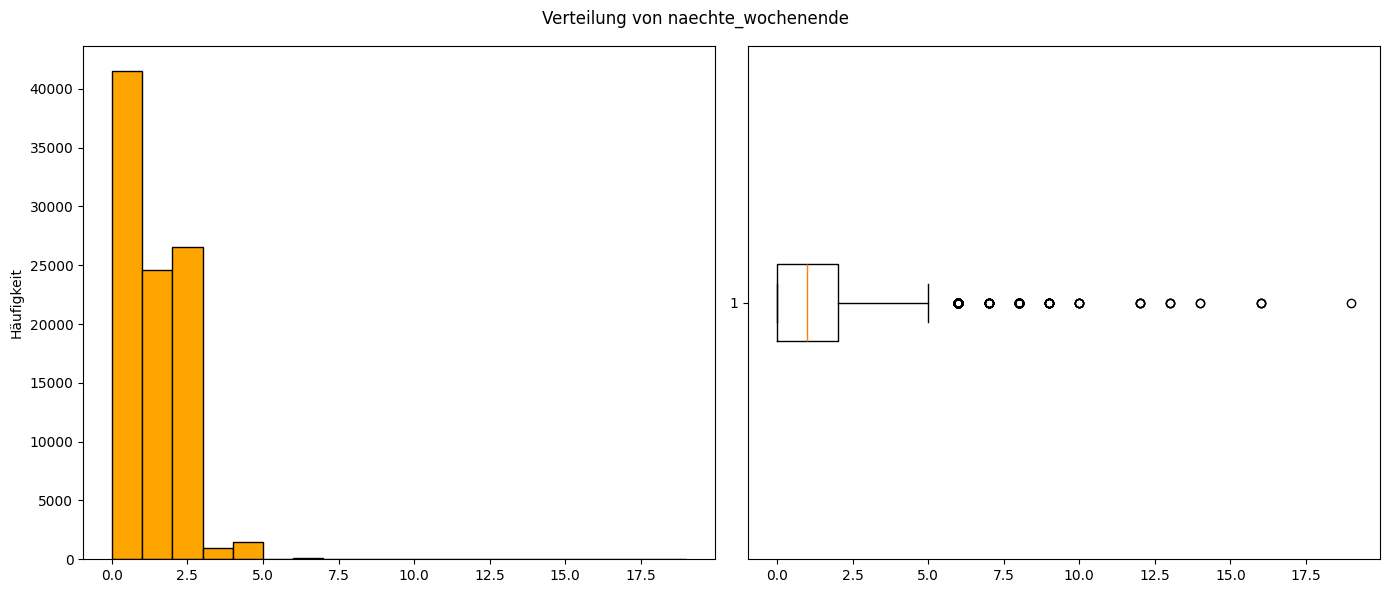

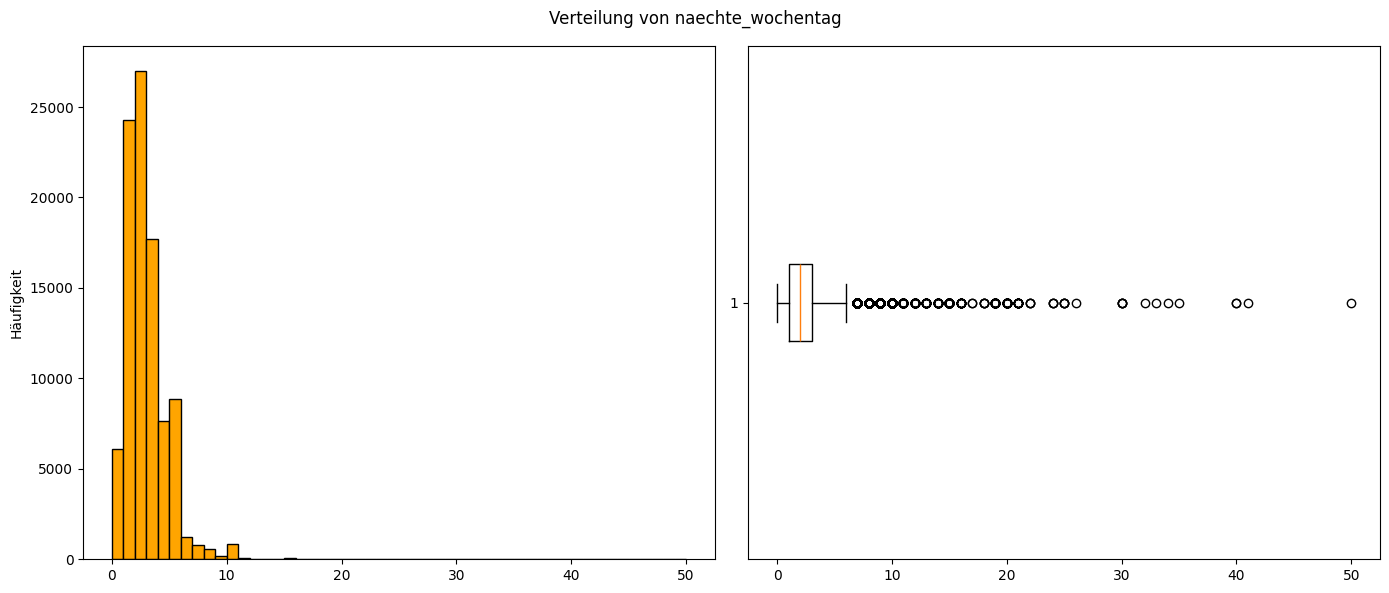

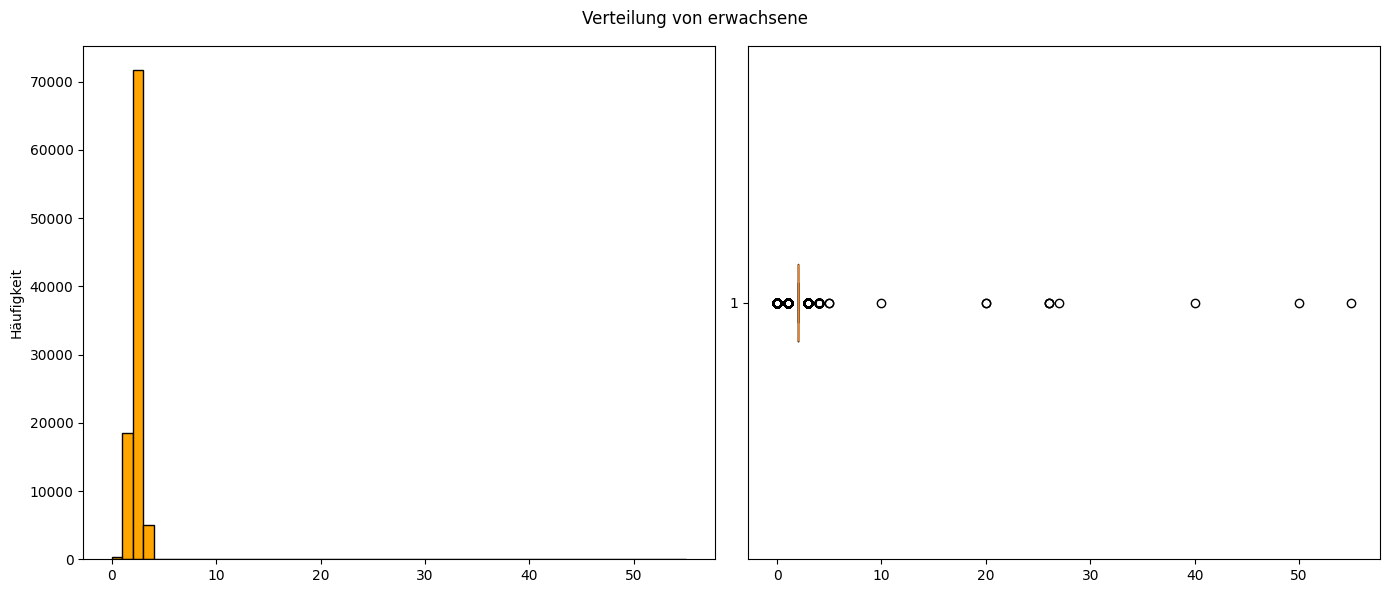

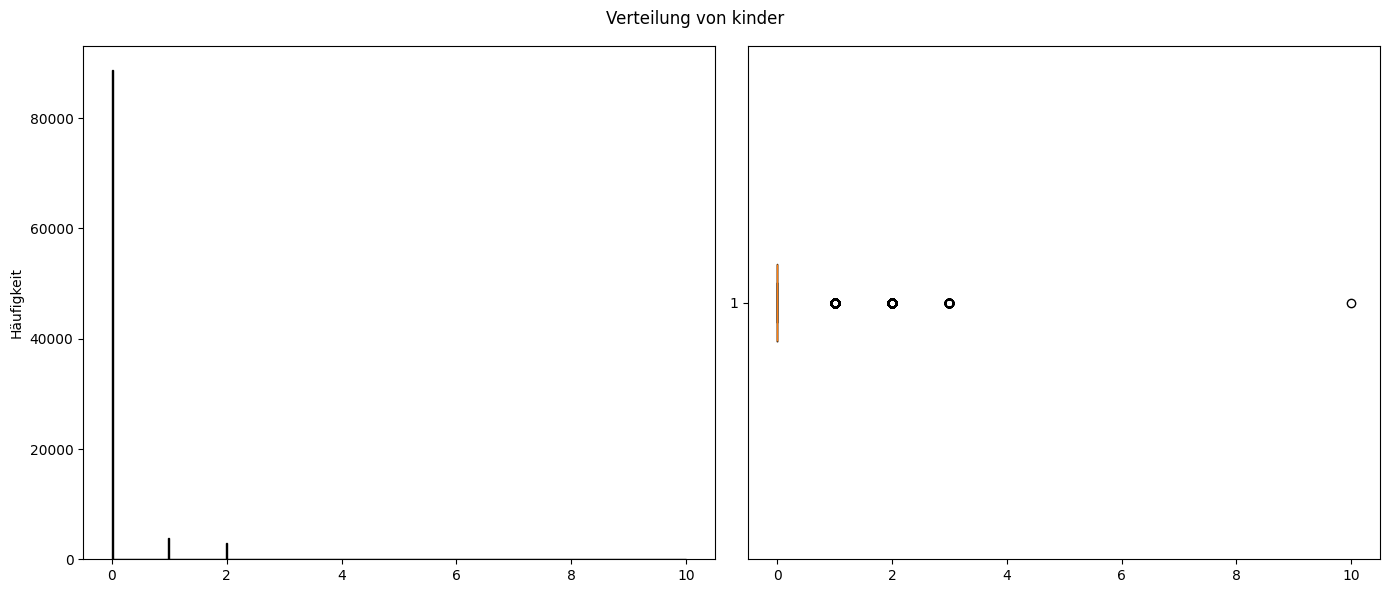

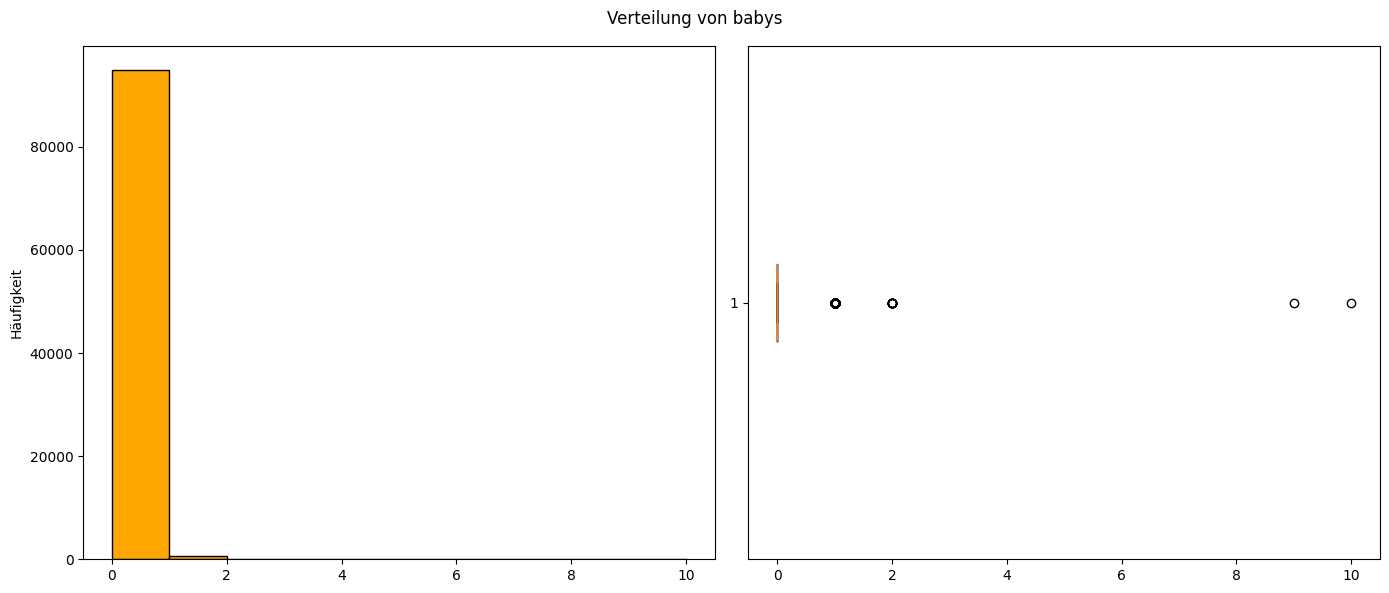

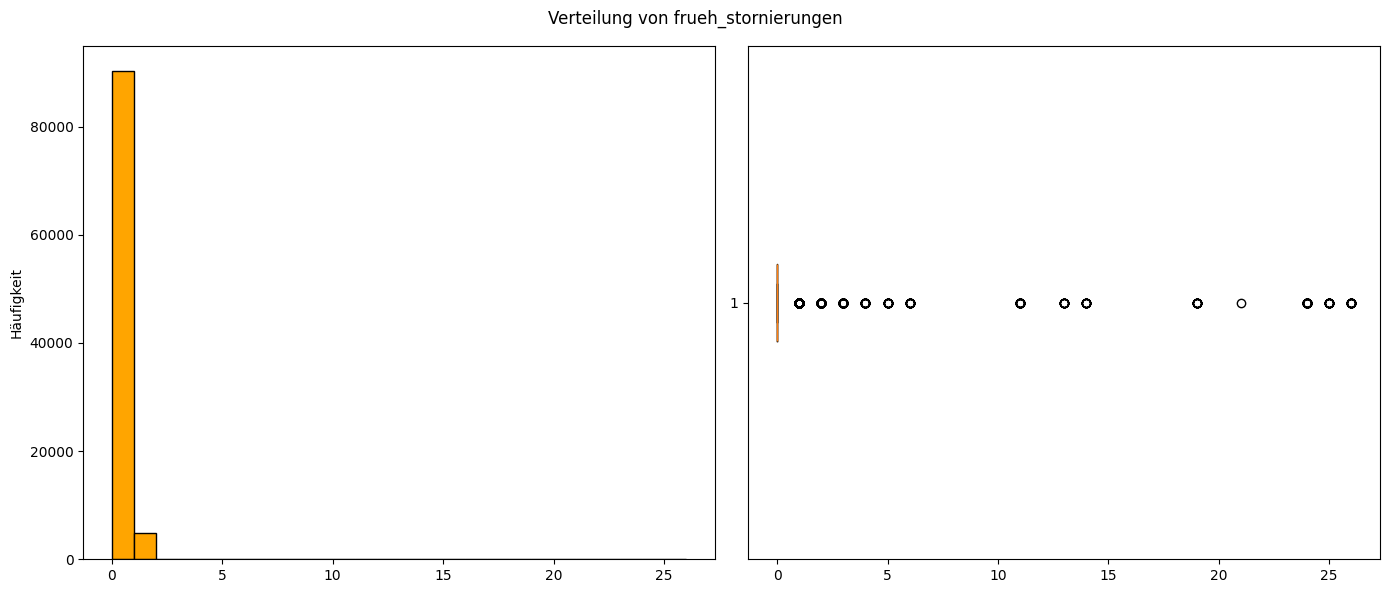

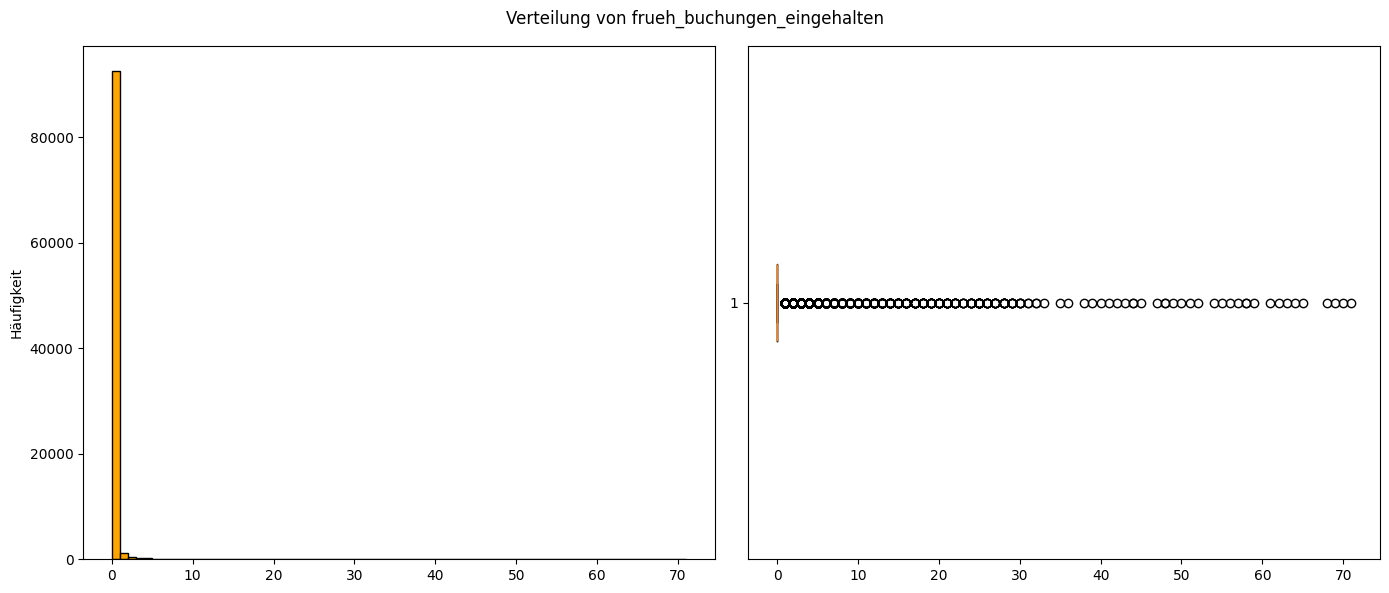

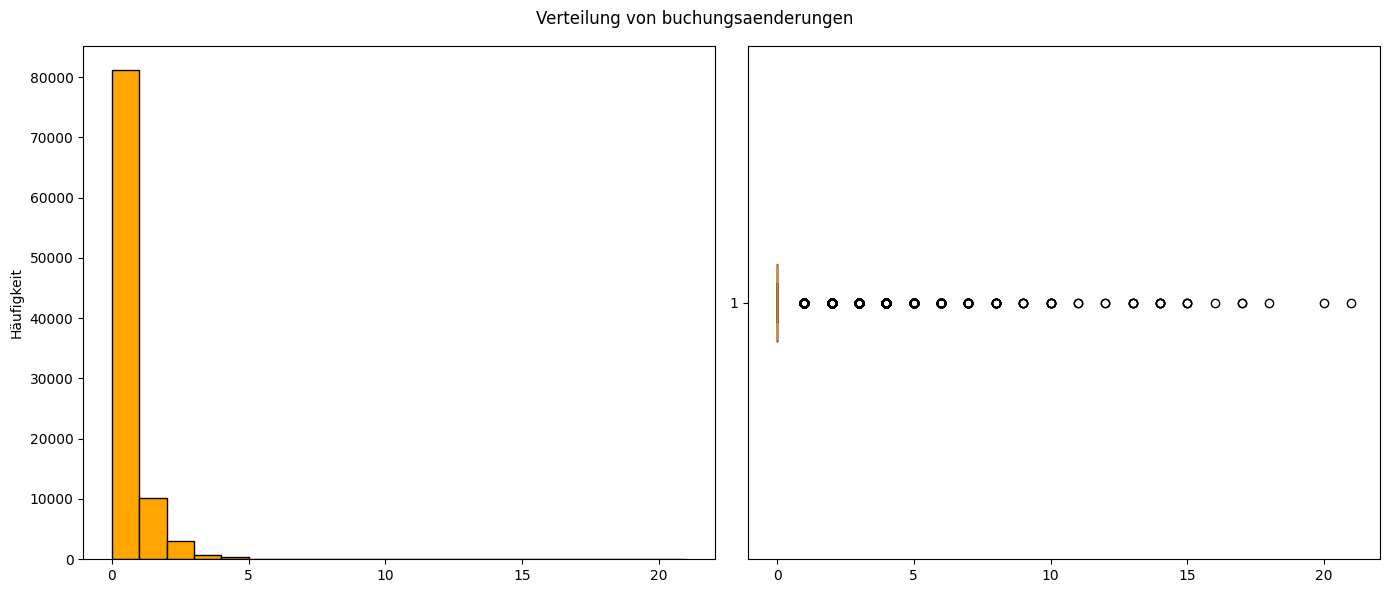

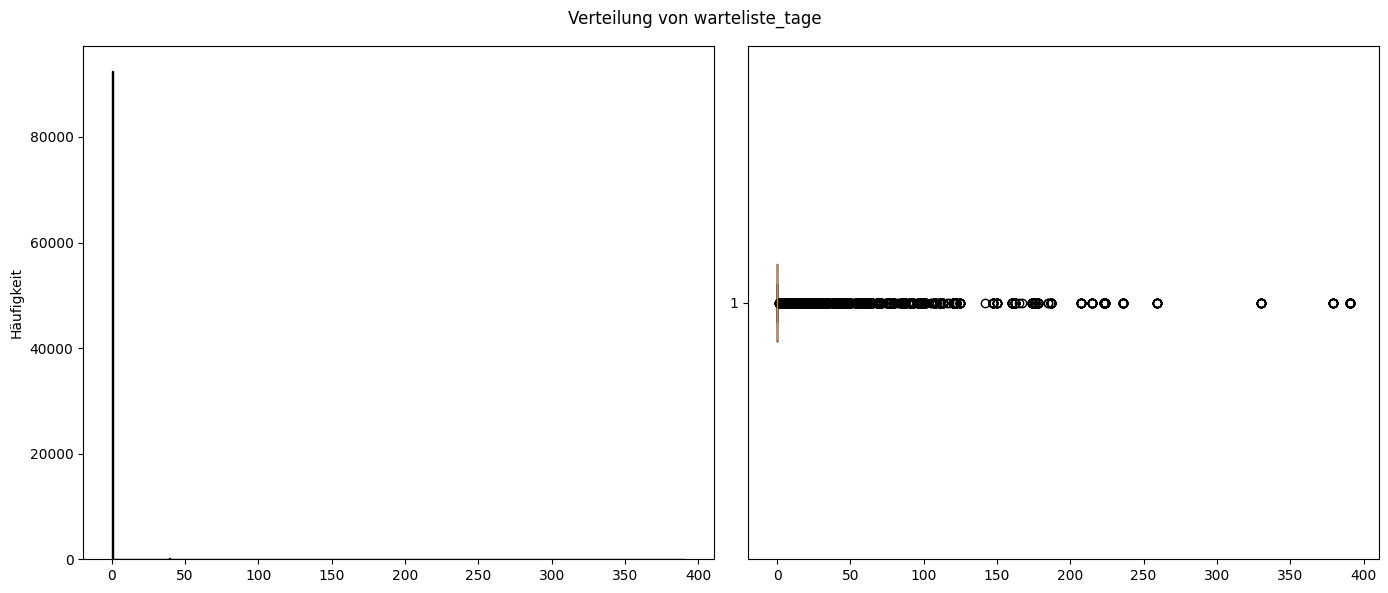

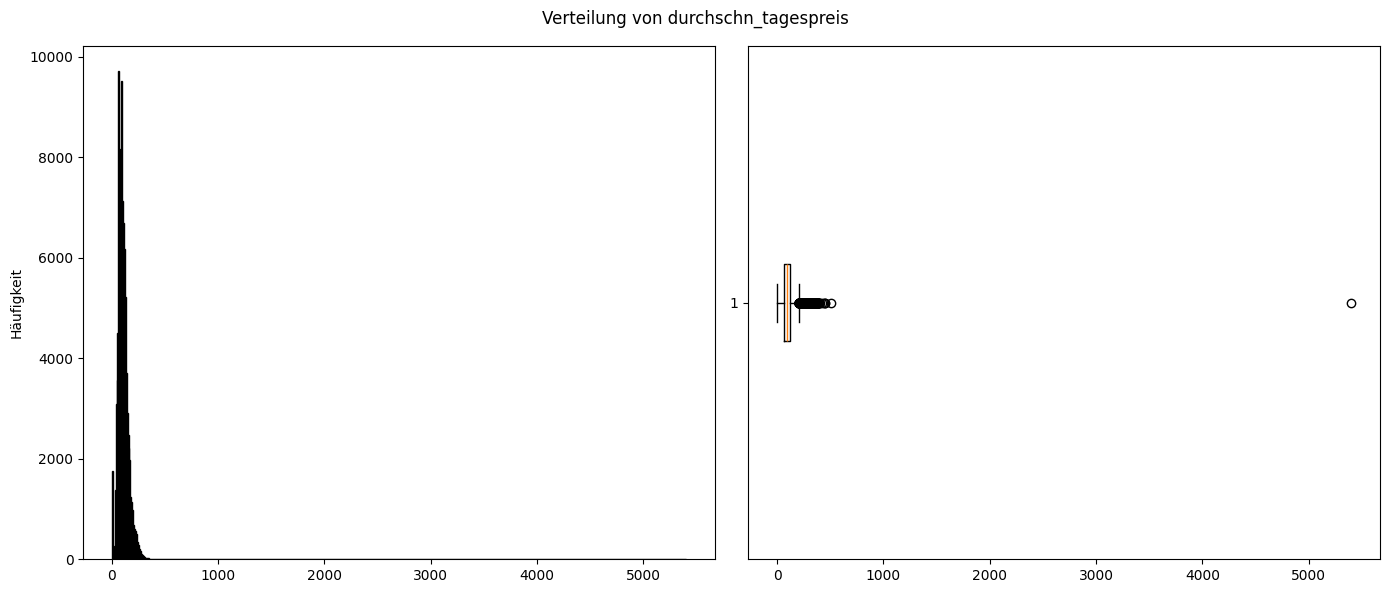

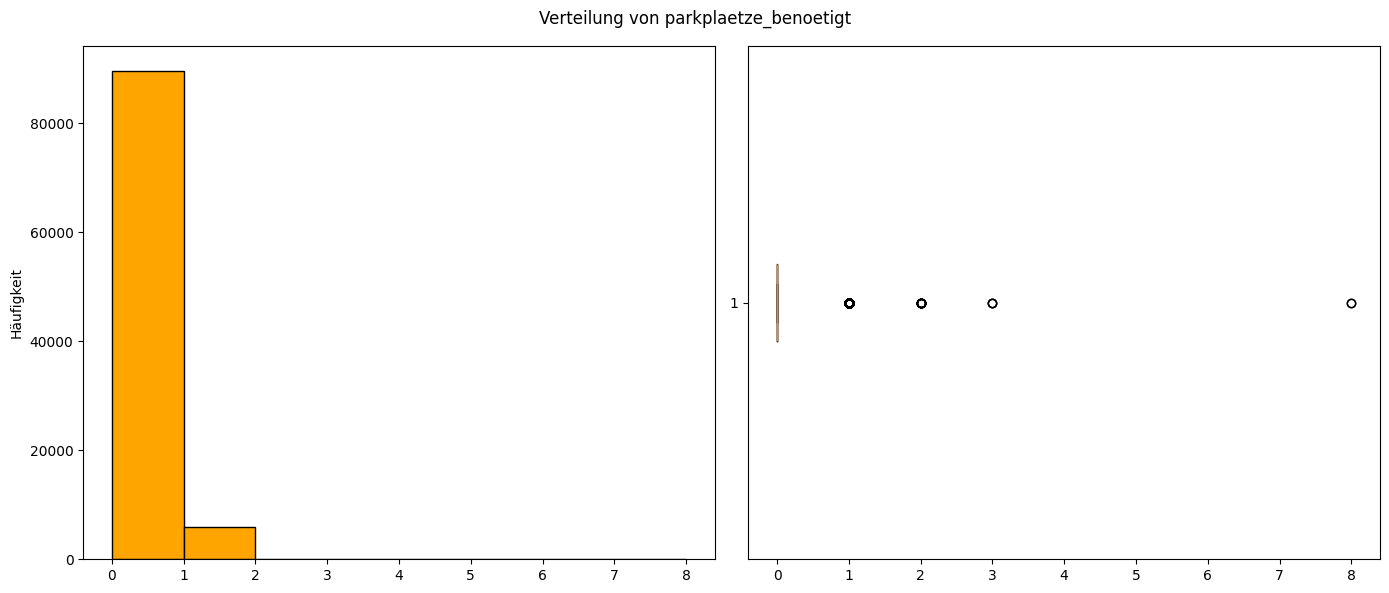

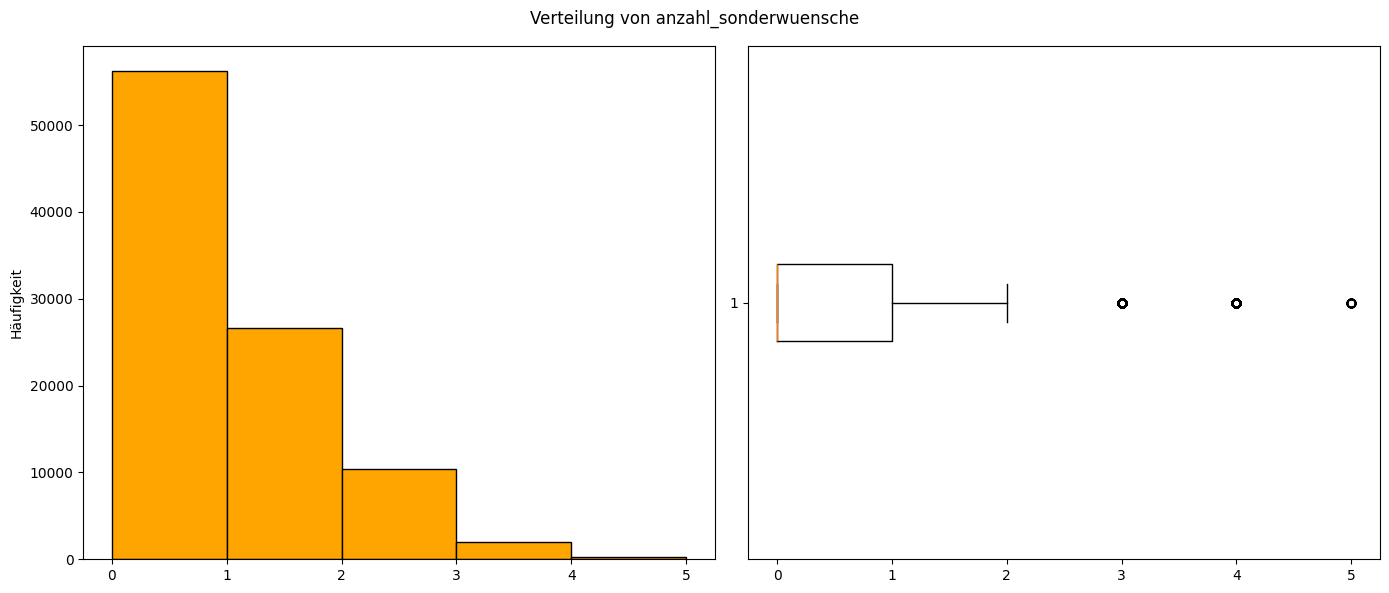

In [29]:
df = df_train.copy()

cancel_rate = float(df.loc[df["storniert"] == 1]["storniert"].count() / df["storniert"].count() * 100)

df_type = df[df["hotel_typ"] == "Ferienhotel"]
cancel_rate_holiday = float(df_type[df["storniert"] == 1]["storniert"].count() / df["storniert"].count() * 100)

df_type = df[df["hotel_typ"] == "Stadthotel"]
cancel_rate_city = float(df_type[df["storniert"] == 1]["storniert"].count() / df["storniert"].count() * 100)

print(f"Stornierungsraten\nGesamt:       {cancel_rate:.2f} %\nFerienhotel:   {cancel_rate_holiday:.2f} %\nStadthotel:   {cancel_rate_city:.2f} %\n")

for column in df.select_dtypes(include=np.number).columns.drop(["storniert", "stammgast", "agentur_id"]):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    fig.suptitle(f"Verteilung von {column}")

    axes[0].hist(df[column].dropna(), bins="auto", color="orange", edgecolor="black")
    axes[0].set_ylabel("Häufigkeit")

    axes[1].boxplot(df[column].dropna(), vert=False)

    plt.tight_layout()
    plt.show()

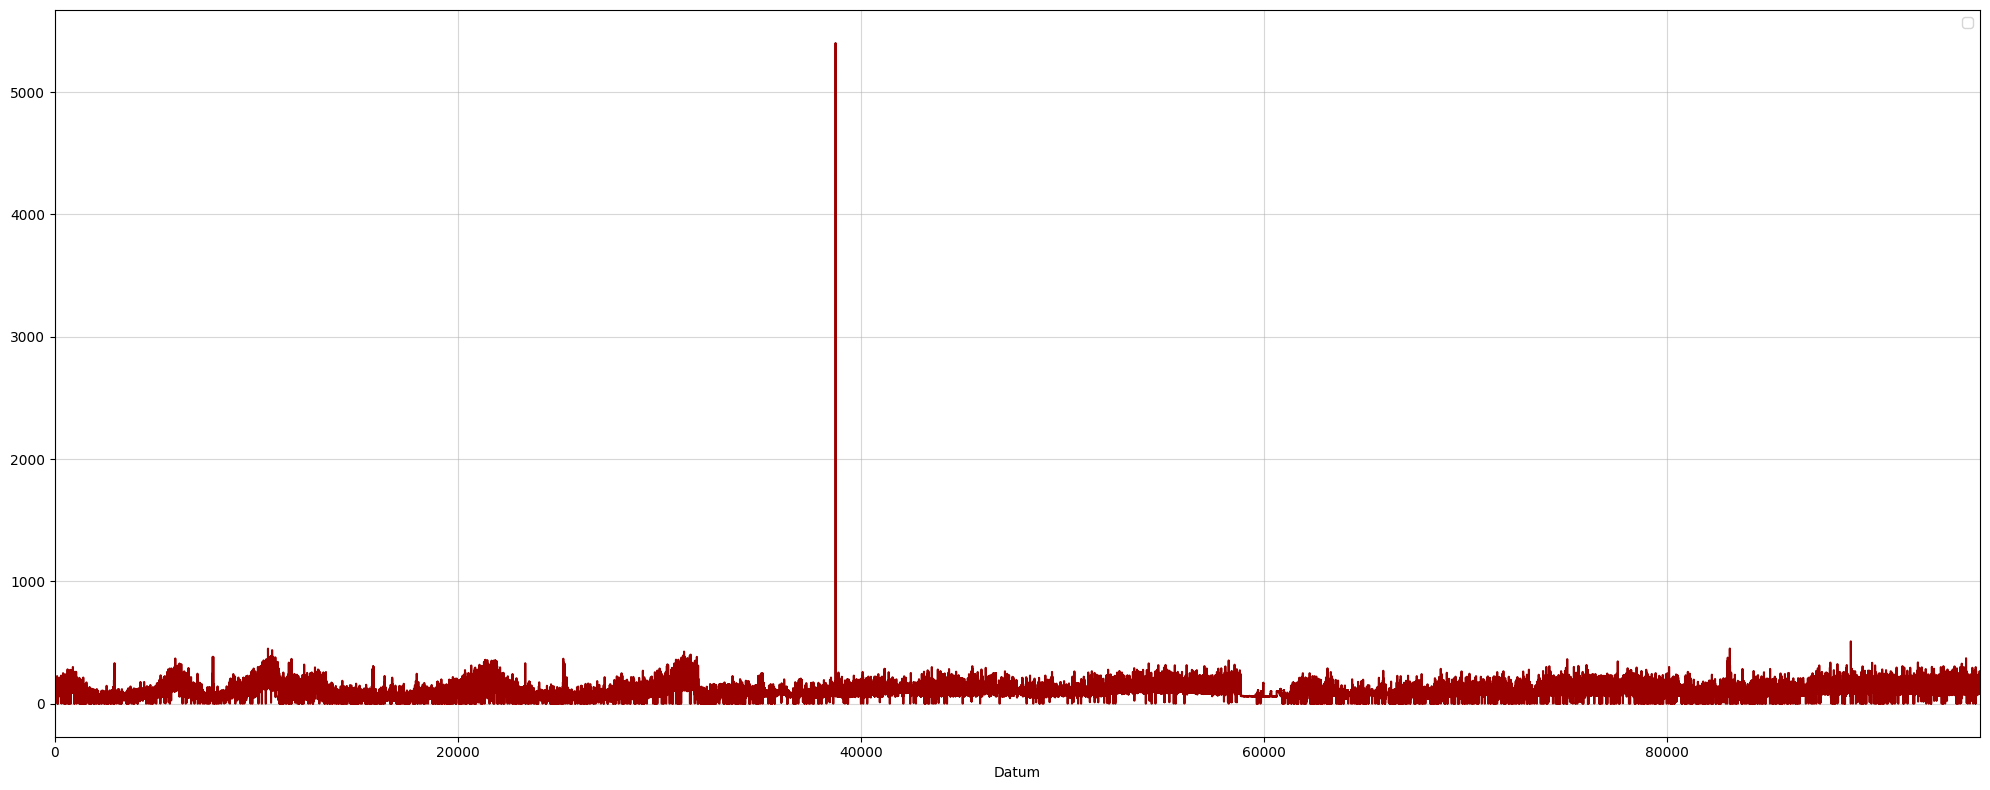

In [30]:
plt.figure(figsize=(20, 8))
# Vorlaufzeit, Tages-preis, Warteliste
plt.plot(df.index, df["durchschn_tagespreis"], color="#9B0000", alpha=1)

plt.xlabel("Datum")
plt.grid(alpha=0.5)
plt.margins(x=0)
plt.legend()
plt.tight_layout()
plt.show()

In [31]:
# Duplizierte Datenpunkte entfernen (hier vor dem Split)
# TODO: Fragen, ob Duplikate unsaubere Daten sind oder tatsächlich Bedeutung haben: 2 verschiedene Gäste haben die gleiche Buchung
print(f"Anzahl Duplikate: {df_train.duplicated().sum()}")
df_train = df_train.drop_duplicates()

# Anpassung von Datentypen zur Verarbeitung
df_train["anreisedatum"] = pd.to_datetime(df_train["anreisedatum"])
df_train["stammgast"] = df_train["stammgast"].astype(str)  # Stammgast ist kategorisch
df_train["agentur_id"] = df_train["agentur_id"].astype(str)  # Agenturen sind kategorisch

df_test["anreisedatum"] = pd.to_datetime(df_test["anreisedatum"])
df_test["stammgast"] = df_test["stammgast"].astype(str)
df_test["agentur_id"] = df_test["agentur_id"].astype(str)

Anzahl Duplikate: 286


In [32]:
# Anzahl Feiertage im Buchungszeitraum - Vorerst einfach als Idee, keine Ahnung ob sinnvoll
df_holidays = pd.read_csv("data/portugal_feiertage.csv")
df_holidays["datum"] = pd.to_datetime(df_holidays["datum"])
df_holidays = df_holidays.set_index("datum")


def map_holidays(df: pd.DataFrame) -> None:
    df["abreisedatum"] = df["anreisedatum"] + pd.to_timedelta((df["naechte_wochenende"] + df["naechte_wochentag"]), unit="D")

    # df["aufenthaltsdauer"] = (df["naechte_wochenende"] + df["naechte_wochentag"])

    df["anzahl_feiertage"] = 0
    for d in df_holidays.index:
        df["anzahl_feiertage"] += ((df["anreisedatum"] <= d) & (df["abreisedatum"] >= d)).astype(int)

    df.drop(columns=["abreisedatum"], inplace=True)


map_holidays(df_train)
map_holidays(df_test)

In [33]:
# Ideen für Features

# Monate / Saison als Feature über anreisedatum
# Frühere Buchung / Stornierung in Prozent
# Frühere Stornierung in Quadrat
# Vorlaufzeit = 0 als Feature (vor Ort)
# Aufenthaltsdauer
# Erwachsene / Kinder / Babys OHE

In [34]:
# TODO: Split erst nach kompletter EDA
from sklearn.model_selection import train_test_split

# Entfernen von nicht relevanten Spalten
# TODO: Ist reservierungsstatus == storniert? Oder gibt es Abweichungen
# TODO: Bedeutung reservierungsstatus datum?  Wirklich irrelevant?
df_train = df_train.drop(columns=["anreisedatum", "reservierungsstatus", "reservierungsstatus_datum"])

# Im Folgendem wird nur noch der Trainingsdatensatz betrachtet um Data Leakage zu vermeiden
X_train, X_valid, y_train, y_valid = train_test_split(
    df_train.drop(columns=["storniert"]),
    df_train.pop("storniert"),  # TODO: drop und pop beides notwendig? reicht nicht pop?
    test_size=0.2,
    random_state=42,
)

categorical = X_train.select_dtypes(exclude=np.number).columns
numerical = X_train.select_dtypes(include=np.number).columns

In [35]:
print(f"Kategorische Features ({len(categorical)}):\n")
for col in categorical:
    n_unique = X_train[col].nunique()
    print(f"{col:25} {n_unique:5} eindeutige Werte")

Kategorische Features (11):

hotel_typ                     2 eindeutige Werte
verpflegung                   5 eindeutige Werte
herkunftsland               168 eindeutige Werte
marktsegment                  8 eindeutige Werte
buchungskanal                 5 eindeutige Werte
stammgast                     2 eindeutige Werte
gebuchter_zimmertyp          10 eindeutige Werte
zugewiesener_zimmertyp       12 eindeutige Werte
anzahlungsart                 3 eindeutige Werte
agentur_id                  320 eindeutige Werte
kundentyp                     4 eindeutige Werte


In [36]:
import country_converter as coco

# Manche Einträge kann country-converter nicht zuordnen
# Die Tabelle: https://de.wikipedia.org/wiki/ISO-3166-1-Kodierliste
# hat eine vollständige Liste und führt auch veraltete Codes auf
MANUAL_CONTINENT_MAPPING = {
    "TMP": "Asia",  # Osttimor (veraltet), aktueller Code: TLS
}


def add_herkunftsland_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Ersetzt 'herkunftsland' durch zwei neue Features:
    - 'herkunftskontinent': Kontinent des Herkunftslandes
    - 'aus_portugal':       1 wenn Herkunftsland Portugal (PRT), sonst 0
    """
    cc = coco.CountryConverter()
    df = df.copy()

    # Binäres Feature: Gast kommt aus Portugal
    df["aus_portugal"] = (df["herkunftsland"] == "PRT").astype(int)

    def map_continent(code):
        if pd.isna(code):
            return "Unbekannt"
        if code in MANUAL_CONTINENT_MAPPING:
            return MANUAL_CONTINENT_MAPPING[code]
        return cc.convert(code, to="continent")

    df["herkunftskontinent"] = df["herkunftsland"].apply(map_continent)
    df = df.drop(columns=["herkunftsland"])
    return df


X_train = add_herkunftsland_features(X_train)
X_valid = add_herkunftsland_features(X_valid)

# Feature-Listen anpassen:
categorical = categorical.drop("herkunftsland")
categorical = categorical.append(pd.Index(["herkunftskontinent", "aus_portugal"]))

# Ergebnis prüfen
print("Verteilung Kontinente (Trainingsdaten):")
print(X_train["herkunftskontinent"].value_counts())
print(f"\nAnteil Gäste aus Portugal: {X_train['aus_portugal'].mean():.1%}")

Verteilung Kontinente (Trainingsdaten):
herkunftskontinent
Europe        68800
America        3194
Asia           2818
Africa          725
Oceania         341
Unbekannt       300
Antarctica        2
Name: count, dtype: int64

Anteil Gäste aus Portugal: 40.5%


In [37]:
X_train[categorical]

,hotel_typ,verpflegung,marktsegment,buchungskanal,stammgast,gebuchter_zimmertyp,zugewiesener_zimmertyp,anzahlungsart,agentur_id,kundentyp,herkunftskontinent,aus_portugal
76374,Stadthotel,Frühstück,Online Reisebüro,Reisebüro,0,D,K,Ohne Anzahlung,9.0,Einzelbucher,Europe,1
66460,Stadthotel,Frühstück,Direktbuchung,Direkt,0,D,D,Ohne Anzahlung,NaN,Einzelbucher,Europe,1
82131,Stadthotel,Frühstück,Offline Reisebüro,Reisebüro,0,A,A,Ohne Anzahlung,28.0,Einzelbucher,Europe,0
44586,Stadthotel,Frühstück,Online Reisebüro,Reisebüro,0,D,D,Ohne Anzahlung,9.0,Einzelbucher,Europe,0
49014,Stadthotel,Frühstück,Direktbuchung,Direkt,0,A,A,Ohne Anzahlung,NaN,Einzelbucher,Europe,1
...,...,...,...,...,...,...,...,...,...,...,...,...
6277,Ferienhotel,Frühstück,Online Reisebüro,Reisebüro,0,G,G,Ohne Anzahlung,240.0,Einzelbucher,Africa,0
55072,Stadthotel,Frühstück,Online Reisebüro,Reisebüro,0,D,D,Ohne Anzahlung,9.0,Einzelbucher,Europe,0
77084,Stadthotel,Frühstück,Offline Reisebüro,Reisebüro,0,D,D,Ohne Anzahlung,22.0,Einzelbucher,Europe,1
860,Ferienhotel,Frühstück,Online Reisebüro,Reisebüro,0,D,E,Ohne Anzahlung,240.0,Einzelbucher,Europe,0


In [38]:
from sklearn.preprocessing import OneHotEncoder


def show_correlations(df: pd.DataFrame, target: pd.DataFrame) -> None:
    df_corr = df.copy()
    df_corr["storniert"] = target.copy()

    correlations = df_corr.corr()
    display(correlations["storniert"].sort_values(ascending=False))


# Korrelation der numerischen Features / Storniert
show_correlations(X_train[numerical], y_train)

# Korrelation der kategorischen Features / Storniert
encoding = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

categorical_without_agentur = categorical.drop("agentur_id") # TODO: OHE ist hier nicht sinnvoll (über 300 unterschiedliche Einträge), zuerst müssen die Spalten anders zusammengefasst werden
df_encoded = encoding.fit_transform(X=X_train[categorical_without_agentur])
df_encoded = pd.DataFrame(df_encoded, columns=encoding.get_feature_names_out(), index=X_train.index)

show_correlations(df_encoded, y_train)

storniert                      1.000000
vorlaufzeit_tage               0.291703
frueh_stornierungen            0.111456
erwachsene                     0.059906
warteliste_tage                0.051933
durchschn_tagespreis           0.044816
anzahl_feiertage               0.035741
naechte_wochentag              0.024607
kinder                         0.008338
naechte_wochenende             0.001288
babys                         -0.031539
frueh_buchungen_eingehalten   -0.057070
buchungsaenderungen           -0.141515
parkplaetze_benoetigt         -0.194634
anzahl_sonderwuensche         -0.235324
Name: storniert, dtype: float64

storniert                         1.000000
anzahlungsart_Nicht erstattbar    0.478201
aus_portugal_1                    0.333968
marktsegment_Gruppen              0.219147
zugewiesener_zimmertyp_A          0.196030
                                    ...   
hotel_typ_Ferienhotel            -0.132513
buchungskanal_Direkt             -0.151186
marktsegment_Direktbuchung       -0.152973
aus_portugal_0                   -0.333968
anzahlungsart_Ohne Anzahlung     -0.474224
Name: storniert, Length: 61, dtype: float64

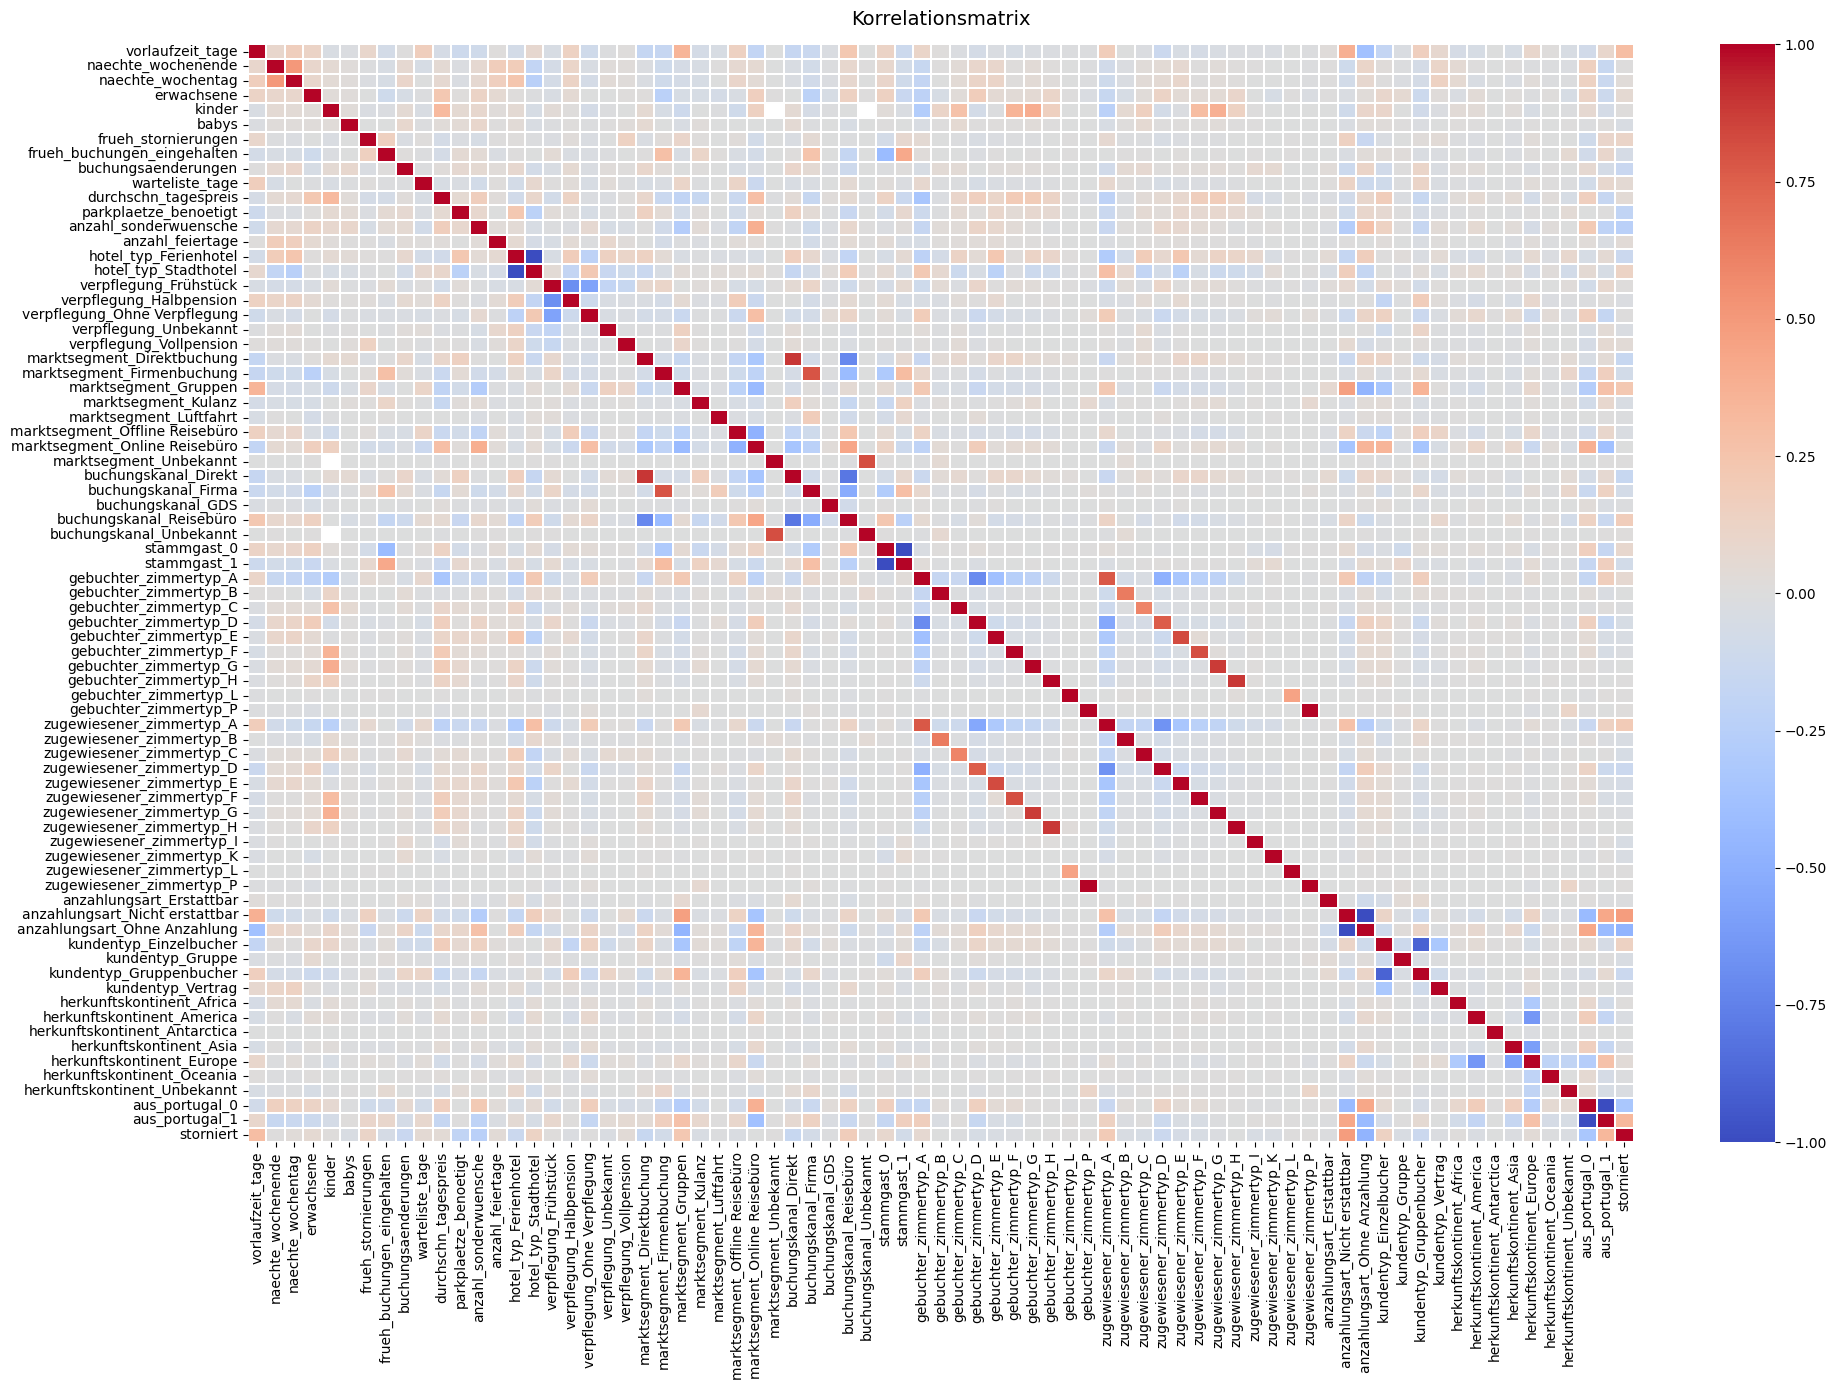

In [39]:
import seaborn as sns

# Numerische Features und Zielvariable ergänzen für Korrelationsmatrix
df_heatmap = pd.concat([X_train[numerical], df_encoded], axis=1)
df_heatmap["storniert"] = y_train

corr = df_heatmap.corr()

fig, ax = plt.subplots(figsize=(20, 14))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.3,
    annot=False,
    ax=ax,
)
ax.set_title("Korrelationsmatrix", fontsize=14, pad=14)
plt.tight_layout()
plt.show()

In [40]:
# Spalten die fehlende Werte enthalten ausgeben
missing = X_train.isna().sum()
display(missing[missing > 0])

# Ausreißern veranschaulichen
display(X_train.select_dtypes(include=np.number).describe(percentiles=[0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.995, 0.999]))

kinder            3
agentur_id    10391
dtype: int64

,vorlaufzeit_tage,naechte_wochenende,naechte_wochentag,erwachsene,kinder,babys,frueh_stornierungen,frueh_buchungen_eingehalten,buchungsaenderungen,warteliste_tage,durchschn_tagespreis,parkplaetze_benoetigt,anzahl_sonderwuensche,anzahl_feiertage,aus_portugal
count,76180.000000,76180.000000,76180.000000,76180.000000,76177.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000
mean,103.834602,0.929942,2.498307,1.858112,0.103260,0.007981,0.085757,0.136519,0.220924,2.293712,101.953647,0.062930,0.574587,0.176424,0.405408
std,106.767568,0.998556,1.911787,0.584068,0.397326,0.101392,0.841162,1.488057,0.655072,17.337603,51.788280,0.247444,0.794688,0.411521,0.490974
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5%,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,38.500000,0.000000,0.000000,0.000000,0.000000
10%,3.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.609000,0.000000,0.000000,0.000000,0.000000
25%,18.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,69.310000,0.000000,0.000000,0.000000,0.000000
50%,69.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,94.470000,0.000000,0.000000,0.000000,0.000000
75%,160.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,125.900000,0.000000,1.000000,0.000000,1.000000
90%,264.100000,2.000000,5.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,164.211000,0.000000,2.000000,1.000000,1.000000


In [41]:
# Behandlung fehlender Werte und OneHotEncoding
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="constant", fill_value="Keine Angabe")),  # Herkunftsland und Agenturen
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

In [42]:
# Behandlung fehlender Werte und Ausreißer
from sklearn.preprocessing import FunctionTransformer, StandardScaler


def clip_numericals(X: np.ndarray) -> np.ndarray:
    lower = np.percentile(X, 1, axis=0)
    upper = np.percentile(X, 99, axis=0)

    return np.clip(X, lower, upper)


numerical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="constant", fill_value=0.0)),  # Kinder (keine Angabe = keine Kinder)
        ("clip", FunctionTransformer(clip_numericals, validate=False)),
        ("scaler", StandardScaler()),  # Für logistische Regression
    ]
)

# Aufgabe 4: Training der Modelle

In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score
from sklearn.model_selection import GridSearchCV

preprocessor = ColumnTransformer([("num", numerical_pipeline, numerical), ("cat", categorical_pipeline, categorical)])


def show_metrics(data: pd.DataFrame, pred: pd.DataFrame, title: str = "") -> None:
    tn, fp, fn, tp = confusion_matrix(data, pred).ravel()

    print(
        f"{title}\n"
        f"Accuracy:       {accuracy_score(data, pred):.7f}\n"
        f"Precision:      {precision_score(data, pred):.7f}\n"
        f"Recall:         {recall_score(data, pred):.7f}\n"
        f"False positive: {fp:.7f}\n"
        f"False negative: {fn:.7f}\n"
    )


def show_feature_importances(model, name: str) -> None:
    onehot = model.named_steps["preprocessor"].named_transformers_["cat"].named_steps["onehot"]
    feature_names_cat = onehot.get_feature_names_out(categorical)

    feature_names = numerical.tolist() + feature_names_cat.tolist()

    # Wichtigkeit der Features
    importances = model.named_steps[name].feature_importances_

    df_importances = pd.DataFrame({"feature": feature_names, "importance": importances}).sort_values("importance", ascending=False)

    display(df_importances)

In [44]:
from sklearn.tree import DecisionTreeClassifier

grid_search = GridSearchCV(
    estimator=Pipeline([("preprocessor", preprocessor), ("tree", DecisionTreeClassifier(random_state=42))]),
    param_grid={
        "tree__max_depth": [15, 30],
        "tree__min_samples_split": [25, 100],
        "tree__min_samples_leaf": [20, 50],
        "tree__criterion": ["entropy"],
        # "tree__max_depth": [5, 15, 30],
        # "tree__min_samples_split": [2, 25, 100],
        # "tree__min_samples_leaf": [2, 20, 50],
        # "tree__criterion": ["gini", "entropy"],
    },
    scoring="accuracy",
    cv=2,
    n_jobs=-1,  # =1 für Ausgabe
    verbose=3,
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_train)
show_metrics(y_train, y_pred, title="Entscheidungsbaum (Trainingsdaten)")

y_pred = best_model.predict(X_valid)
show_metrics(y_valid, y_pred, title="Entscheidungsbaum (Testdaten)")

print("Beste Parameter:", grid_search.best_params_)

show_feature_importances(best_model, "tree")

Fitting 2 folds for each of 8 candidates, totalling 16 fits
[CV 1/2] END tree__criterion=entropy, tree__max_depth=15, tree__min_samples_leaf=20, tree__min_samples_split=100;, score=0.845 total time=   1.5s
[CV 2/2] END tree__criterion=entropy, tree__max_depth=15, tree__min_samples_leaf=20, tree__min_samples_split=25;, score=0.846 total time=   1.6s
[CV 1/2] END tree__criterion=entropy, tree__max_depth=15, tree__min_samples_leaf=20, tree__min_samples_split=25;, score=0.844 total time=   1.7s
[CV 2/2] END tree__criterion=entropy, tree__max_depth=15, tree__min_samples_leaf=20, tree__min_samples_split=100;, score=0.846 total time=   1.5s
[CV 1/2] END tree__criterion=entropy, tree__max_depth=15, tree__min_samples_leaf=50, tree__min_samples_split=25;, score=0.841 total time=   1.5s
[CV 2/2] END tree__criterion=entropy, tree__max_depth=15, tree__min_samples_leaf=50, tree__min_samples_split=25;, score=0.846 total time=   1.4s
[CV 1/2] END tree__criterion=entropy, tree__max_depth=15, tree__min_

,feature,importance
59,anzahlungsart_Nicht erstattbar,0.326963
27,marktsegment_Online Reisebüro,0.116217
0,vorlaufzeit_tage,0.088896
12,anzahl_sonderwuensche,0.060632
11,parkplaetze_benoetigt,0.055241
...,...,...
170,agentur_id_251.0,0.000000
171,agentur_id_252.0,0.000000
147,agentur_id_219.0,0.000000
148,agentur_id_22.0,0.000000


In [45]:
from sklearn.linear_model import LogisticRegression

grid_search = GridSearchCV(
    estimator=Pipeline([("preprocessor", preprocessor), ("logistic", LogisticRegression(random_state=42))]),
    param_grid={
        "logistic__C": [0.01, 0.1, 1, 10],
        "logistic__penalty": ["l2"],
        "logistic__solver": ["lbfgs"],
        "logistic__max_iter": [500],
    },
    scoring="accuracy",
    cv=5,
    n_jobs=-1,
    verbose=3,
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_train)
show_metrics(y_train, y_pred, title="Logistische Regression (Trainingsdaten)")

y_pred = best_model.predict(X_valid)
show_metrics(y_valid, y_pred, title="Logistische Regression (Testdaten)")

print("Beste Parameter:", grid_search.best_params_)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
[CV 1/5] END logistic__C=0.01, logistic__max_iter=500, logistic__penalty=l2, logistic__solver=lbfgs;, score=0.825 total time=   0.8s
[CV 2/5] END logistic__C=0.01, logistic__max_iter=500, logistic__penalty=l2, logistic__solver=lbfgs;, score=0.822 total time=   0.9s
[CV 3/5] END logistic__C=0.01, logistic__max_iter=500, logistic__penalty=l2, logistic__solver=lbfgs;, score=0.820 total time=   1.0s
[CV 5/5] END logistic__C=0.01, logistic__max_iter=500, logistic__penalty=l2, logistic__solver=lbfgs;, score=0.825 total time=   1.0s
[CV 4/5] END logistic__C=0.01, logistic__max_iter=500, logistic__penalty=l2, logistic__solver=lbfgs;, score=0.828 total time=   1.1s
[CV 1/5] END logistic__C=0.1, logistic__max_iter=500, logistic__penalty=l2, logistic__solver=lbfgs;, score=0.827 total time=   2.0s
[CV 2/5] END logistic__C=0.1, logistic__max_iter=500, logistic__penalty=l2, logistic__solver=lbfgs;, score=0.825 total time=   1.9s
[CV 3/5] EN

In [46]:
from sklearn.ensemble import RandomForestClassifier

grid_search = GridSearchCV(
    estimator=Pipeline([("preprocessor", preprocessor), ("rf", RandomForestClassifier(random_state=42))]),
    param_grid={
        "rf__n_estimators": [200],
        "rf__max_depth": [None],
        "rf__min_samples_split": [50],
        "rf__max_features": ["sqrt"],
        # "rf__n_estimators": [100, 200],
        # "rf__max_depth": [10, 20, None],
        # "rf__min_samples_split": [2, 10, 50],
        # "rf__max_features": ["sqrt", "log2"],
    },
    scoring="accuracy",
    cv=2,
    n_jobs=-1,
    verbose=3,
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_train)
show_metrics(y_train, y_pred, title="Random Forest (Trainingsdaten)")

y_pred = best_model.predict(X_valid)
show_metrics(y_valid, y_pred, title="Random Forest (Testdaten)")

print("Beste Parameter:", grid_search.best_params_)

show_feature_importances(best_model, "rf")

Fitting 2 folds for each of 1 candidates, totalling 2 fits
[CV 1/2] END rf__max_depth=None, rf__max_features=sqrt, rf__min_samples_split=50, rf__n_estimators=200;, score=0.864 total time=  25.2s
[CV 2/2] END rf__max_depth=None, rf__max_features=sqrt, rf__min_samples_split=50, rf__n_estimators=200;, score=0.865 total time=  25.3s
Random Forest (Trainingsdaten)
Accuracy:       0.8904306
Precision:      0.9015542
Recall:         0.7895728
False positive: 2426.0000000
False negative: 5921.0000000

Random Forest (Testdaten)
Accuracy:       0.8725192
Precision:      0.8755723
Recall:         0.7626032
False positive: 761.0000000
False negative: 1667.0000000

Beste Parameter: {'rf__max_depth': None, 'rf__max_features': 'sqrt', 'rf__min_samples_split': 50, 'rf__n_estimators': 200}


,feature,importance
59,anzahlungsart_Nicht erstattbar,9.405211e-02
0,vorlaufzeit_tage,9.281076e-02
60,anzahlungsart_Ohne Anzahlung,7.438803e-02
394,aus_portugal_1,7.073398e-02
393,aus_portugal_0,6.877196e-02
...,...,...
295,agentur_id_433.0,1.380651e-08
294,agentur_id_432.0,9.067186e-10
181,agentur_id_267.0,9.031098e-11
168,agentur_id_25.0,0.000000e+00


In [47]:
from sklearn.ensemble import GradientBoostingClassifier

grid_search = GridSearchCV(
    estimator=Pipeline([("preprocessor", preprocessor), ("gb", GradientBoostingClassifier(random_state=42))]),
    param_grid={
        "gb__n_estimators": [100, 200],
        "gb__learning_rate": [0.05, 0.1],
        "gb__max_depth": [3, 5],
        "gb__min_samples_split": [2, 10],
        "gb__min_samples_leaf": [1, 5],
        "gb__subsample": [0.8, 1.0],
    },
    scoring="accuracy",
    cv=5,
    n_jobs=-1,
    verbose=3,
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_train)
show_metrics(y_train, y_pred, title="Gradient Boosting (Trainingsdaten)")

y_pred = best_model.predict(X_valid)
show_metrics(y_valid, y_pred, title="Gradient Boosting (Testdaten)")

print("Beste Parameter:", grid_search.best_params_)

show_feature_importances(best_model, "gb")

Fitting 5 folds for each of 64 candidates, totalling 320 fits
[CV 3/5] END gb__learning_rate=0.05, gb__max_depth=3, gb__min_samples_leaf=1, gb__min_samples_split=2, gb__n_estimators=100, gb__subsample=0.8;, score=0.841 total time=  14.0s
[CV 2/5] END gb__learning_rate=0.05, gb__max_depth=3, gb__min_samples_leaf=1, gb__min_samples_split=2, gb__n_estimators=100, gb__subsample=0.8;, score=0.837 total time=  14.2s
[CV 4/5] END gb__learning_rate=0.05, gb__max_depth=3, gb__min_samples_leaf=1, gb__min_samples_split=2, gb__n_estimators=100, gb__subsample=0.8;, score=0.840 total time=  14.4s
[CV 1/5] END gb__learning_rate=0.05, gb__max_depth=3, gb__min_samples_leaf=1, gb__min_samples_split=2, gb__n_estimators=100, gb__subsample=0.8;, score=0.846 total time=  14.6s
[CV 5/5] END gb__learning_rate=0.05, gb__max_depth=3, gb__min_samples_leaf=1, gb__min_samples_split=2, gb__n_estimators=100, gb__subsample=0.8;, score=0.843 total time=  14.7s
[CV 4/5] END gb__learning_rate=0.05, gb__max_depth=3, gb__

,feature,importance
59,anzahlungsart_Nicht erstattbar,0.366147
0,vorlaufzeit_tage,0.092046
371,agentur_id_9.0,0.082953
12,anzahl_sonderwuensche,0.070446
159,agentur_id_240.0,0.046388
...,...,...
359,agentur_id_77.0,0.000000
360,agentur_id_78.0,0.000000
361,agentur_id_79.0,0.000000
377,agentur_id_95.0,0.000000


In [48]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

grid_search = GridSearchCV(
    estimator=Pipeline(
        [
            ("preprocessor", preprocessor),
            (
                "stack",
                StackingClassifier(
                    estimators=[
                        ("tree", DecisionTreeClassifier(max_depth=10, min_samples_split=10, random_state=42)),
                        ("gb", GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, max_depth=3, random_state=42)),
                        ("rf", RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42)),
                    ],
                    final_estimator=LogisticRegression(max_iter=500, random_state=42),
                    cv=2,
                    n_jobs=-1,
                ),
            ),
        ]
    ),
    param_grid={"stack__final_estimator__C": [0.1, 1, 10], "stack__final_estimator__penalty": ["l2"]},
    scoring="accuracy",
    cv=2,
    n_jobs=-1,
    verbose=3,
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_train)
show_metrics(y_train, y_pred, title="Stacking (Trainingsdaten)")

y_pred = best_model.predict(X_valid)
show_metrics(y_valid, y_pred, title="Stacking (Testdaten)")

print("Beste Parameter:", grid_search.best_params_)

Fitting 2 folds for each of 3 candidates, totalling 6 fits
[CV 2/2] END stack__final_estimator__C=0.1, stack__final_estimator__penalty=l2;, score=0.861 total time=  20.9s
[CV 2/2] END stack__final_estimator__C=1, stack__final_estimator__penalty=l2;, score=0.863 total time=  20.9s
[CV 2/2] END stack__final_estimator__C=10, stack__final_estimator__penalty=l2;, score=0.862 total time=  20.8s
[CV 1/2] END stack__final_estimator__C=1, stack__final_estimator__penalty=l2;, score=0.861 total time=  21.2s
[CV 1/2] END stack__final_estimator__C=10, stack__final_estimator__penalty=l2;, score=0.861 total time=  21.2s
[CV 1/2] END stack__final_estimator__C=0.1, stack__final_estimator__penalty=l2;, score=0.860 total time=  21.4s
Stacking (Trainingsdaten)
Accuracy:       0.8709241
Precision:      0.8545694
Recall:         0.7839576
False positive: 3754.0000000
False negative: 6079.0000000

Stacking (Testdaten)
Accuracy:       0.8622808
Precision:      0.8415903
Recall:         0.7717175
False positiv

# Aufgabe 5: Evaluation

# Aufgabe 6: Vorhersage auf unbekannten Daten

In [49]:
# Hier dann bestes Modell auf kompletten Datensatz trainieren

X = df_train.drop(columns=["storniert"])
y = df_train.pop("storniert")

KeyError: "['storniert'] not found in axis"

In [ ]:
y_pred = best_model.predict(df_test)

df_test["storniert_pred"] = y_pred
df_test[["buchungs_id", "storniert_pred"]].to_csv("data/vorhersage.csv", index=False)